# MLP with RBF-KAN as activation function: MNIST Dataset

## Import

In [12]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from mlp_rbf_kan.models import MLP_RBFKAN, MLP, KAN, RBF_KAN, train_classification
from mlp_rbf_kan.eval.tools import *
from mlp_rbf_kan.eval.experiments import *

## MNIST Dataset

In [13]:
# -----------------------------
# Dataset
# -----------------------------
iris = load_iris()
X = iris.data
y = iris.target

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Convert to tensors
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=16)

## Training

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
input_dim = 4 
hidden_dim = 32 
output_dim = 3 
centers = 8 # or Knots
domain = (-3, 3)
shared_basis = True

# Models
mlp = MLP(input_dim, hidden_dim, output_dim)
kan = KAN(width=[input_dim, hidden_dim, hidden_dim, output_dim], num_knots=centers, domain=domain) 
rbf_kan = RBF_KAN(input_dim, hidden_dim, output_dim, centers, domain)
mlp_rbf = MLP_RBFKAN(in_dim=input_dim, hidden_dim=hidden_dim, out_dim=output_dim, num_centers=centers, domain=domain, shared_basis=shared_basis)

models = {
    "MLP": mlp,
    "KAN": kan,
    "RBF-KAN": rbf_kan, 
    "MLP+RBF-KAN": mlp_rbf
}

Device: cuda


In [15]:
train_losses_dict = {}
test_losses_dict = {}
metrics_dict = {}

epochs = 40
learning_rate = 0.001

for name, model in models.items():
    print(f"\n--- Training {name} on IRIS ---")
    train_loss, test_loss = train_classification(
        model, train_loader, test_loader, 
        epochs=epochs, lr=learning_rate, device=device
    )
    
    train_losses_dict[name] = train_loss
    test_losses_dict[name] = test_loss
    
    # Evaluation
    metrics = evaluate_classification(model, test_loader, device=device)
    metrics_dict[name] = {"accuracy": metrics["accuracy"], "f1": metrics["f1"], "precision": metrics["precision"], "recall": metrics["recall"], "conf_matrix": metrics["confusion_matrix"]}
    print(f"{name} -> Accuracy: {metrics["accuracy"]:.4f}")


--- Training MLP on IRIS ---


Training Progress: 100%|██████████| 40/40 [00:00<00:00, 47.73it/s, Tr_Loss=0.0925, Te_Loss=0.0742]


MLP -> Accuracy: 0.9667

--- Training KAN on IRIS ---


Training Progress: 100%|██████████| 40/40 [00:03<00:00, 13.32it/s, Tr_Loss=0.0634, Te_Loss=0.0324]


KAN -> Accuracy: 1.0000

--- Training RBF-KAN on IRIS ---


Training Progress: 100%|██████████| 40/40 [00:01<00:00, 22.88it/s, Tr_Loss=0.0357, Te_Loss=0.0187]


RBF-KAN -> Accuracy: 1.0000

--- Training MLP+RBF-KAN on IRIS ---


Training Progress: 100%|██████████| 40/40 [00:01<00:00, 24.74it/s, Tr_Loss=0.0617, Te_Loss=0.0315]

MLP+RBF-KAN -> Accuracy: 1.0000


## Results

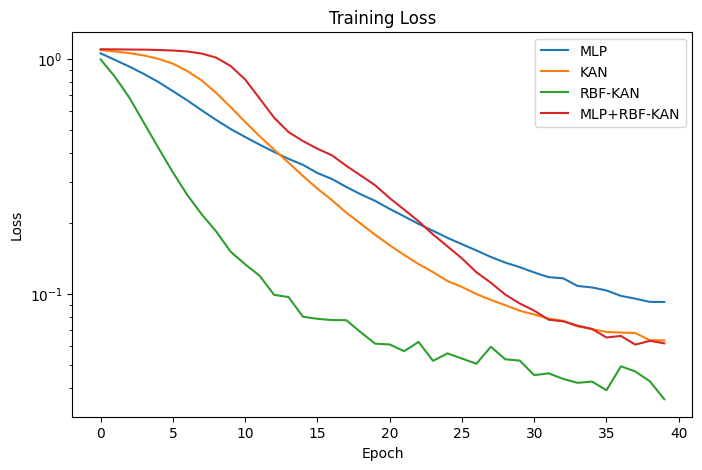

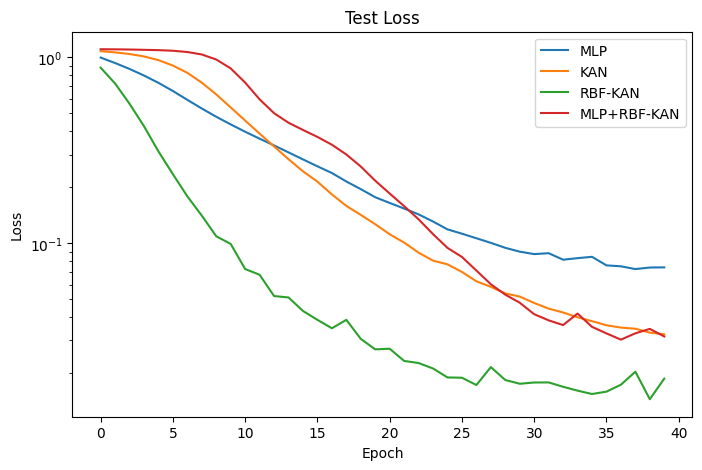

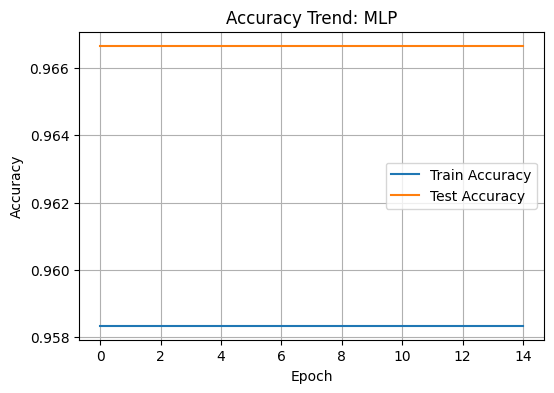

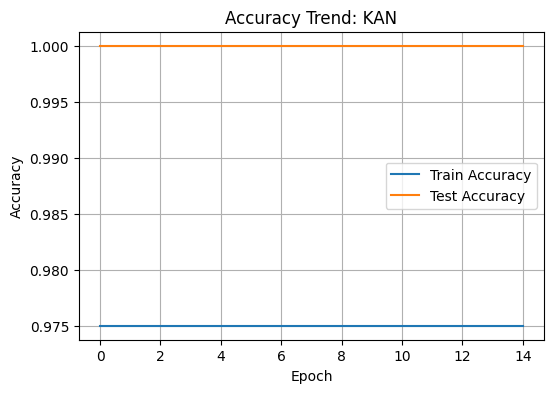

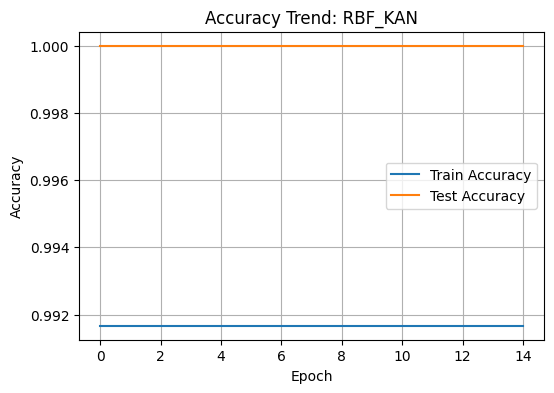

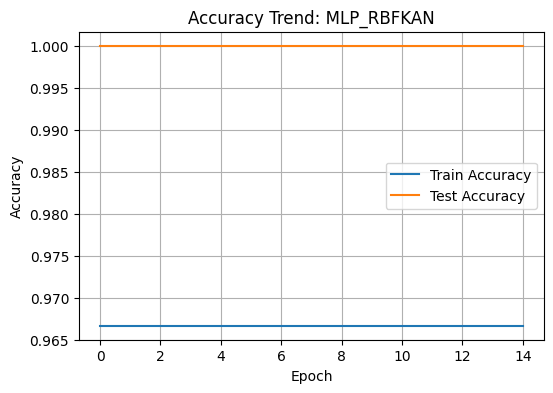

In [16]:
plot_losses(train_losses_dict, "Training Loss")
plot_losses(test_losses_dict, "Test Loss")

for name, model in models.items():
    plot_accuracy_trend(model, train_loader, test_loader, epochs=15, device=device)

In [17]:
print(f"Number of paramters [MLP]: {n_parameters(mlp)}")
print(f"Number of paramters [KAN]: {n_parameters(kan)}")
print(f"Number of paramters [RBF-KAN]: {n_parameters(rbf_kan)}")
print(f"Number of paramters [MLP with RBF-KAN]: {n_parameters(mlp_rbf)}")

Number of paramters [MLP]: 1315
Number of paramters [KAN]: 14976
Number of paramters [RBF-KAN]: 10099
Number of paramters [MLP with RBF-KAN]: 1987


In [18]:
print(metrics_dict)

{'MLP': {'accuracy': 0.9666666666666667, 'f1': 0.9664109121909632, 'precision': 0.9694444444444444, 'recall': 0.9666666666666667, 'conf_matrix': array([[10,  0,  0],
       [ 0,  8,  1],
       [ 0,  0, 11]])}, 'KAN': {'accuracy': 1.0, 'f1': 1.0, 'precision': 1.0, 'recall': 1.0, 'conf_matrix': array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]])}, 'RBF-KAN': {'accuracy': 1.0, 'f1': 1.0, 'precision': 1.0, 'recall': 1.0, 'conf_matrix': array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]])}, 'MLP+RBF-KAN': {'accuracy': 1.0, 'f1': 1.0, 'precision': 1.0, 'recall': 1.0, 'conf_matrix': array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]])}}



MLP Confusion Matrix:


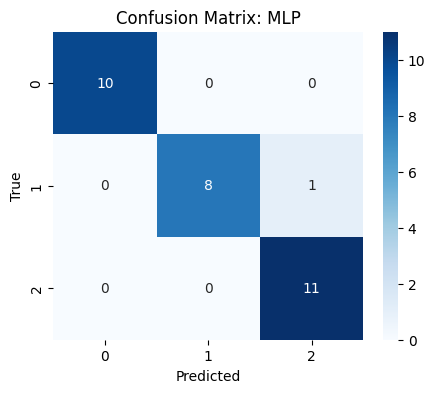


KAN Confusion Matrix:


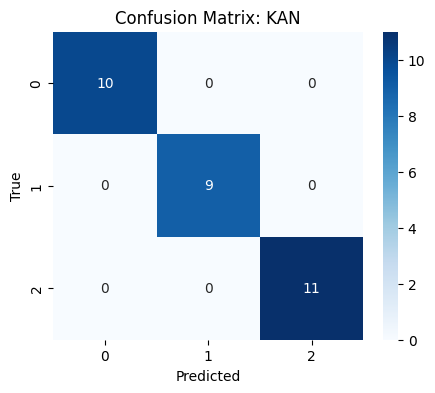


RBF-KAN Confusion Matrix:


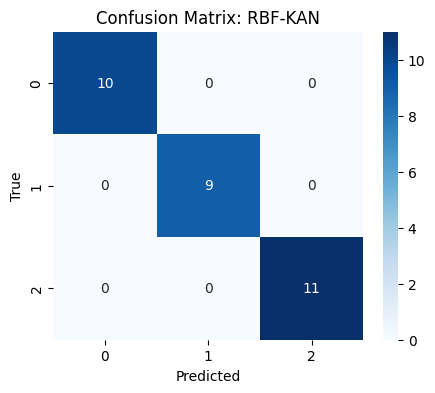


MLP+RBF-KAN Confusion Matrix:


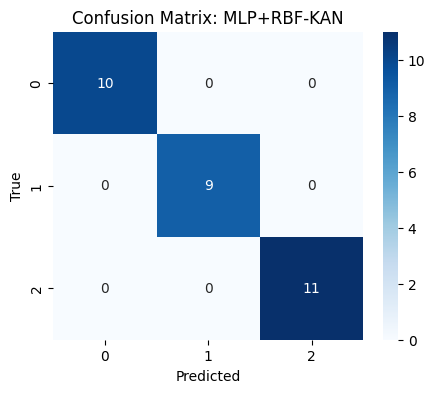

In [19]:
mnist_classes = [str(i) for i in range(3)]

for name, metrics in metrics_dict.items():
    print(f"\n{name} Confusion Matrix:")
    plot_confusion_matrix(metrics["conf_matrix"], classes=mnist_classes, model_name=name)

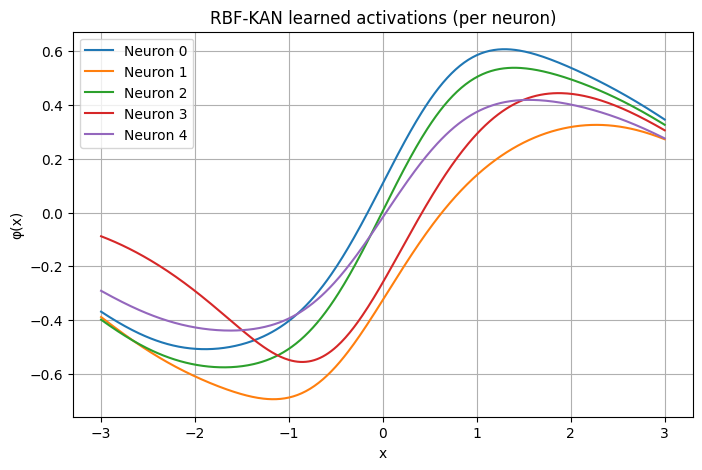

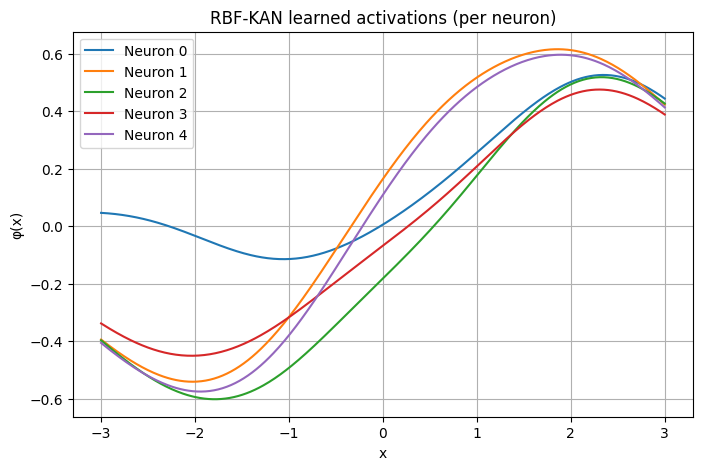

In [22]:
plot_rbf_neurons(mlp_rbf.act1)
plot_rbf_neurons(mlp_rbf.act2)

## Model Comparison: IRIS


=== Running seed 2 ===


Training Progress: 100%|██████████| 20/20 [00:00<00:00, 26.04it/s, Tr_Loss=0.2570, Te_Loss=0.2019]



=== Running seed 235 ===


Training Progress: 100%|██████████| 20/20 [00:00<00:00, 25.62it/s, Tr_Loss=0.2502, Te_Loss=0.1775]



=== Running seed 1 ===


...


=== Running seed 43 ===


Training Progress: 100%|██████████| 20/20 [00:00<00:00, 24.36it/s, Tr_Loss=0.1978, Te_Loss=0.1313]



=== Running seed 89 ===


Training Progress: 100%|██████████| 20/20 [00:00<00:00, 26.05it/s, Tr_Loss=0.2111, Te_Loss=0.1360]



================ FINAL RESULTS (mean ± std) ================

MLP
  accuracy: 9.600000e-01 ± 2.49e-02
  precision: 9.652137e-01 ± 2.09e-02
  recall: 9.600000e-01 ± 2.49e-02
  f1: 9.593421e-01 ± 2.55e-02

KAN
  accuracy: 9.733333e-01 ± 1.33e-02
  precision: 9.755556e-01 ± 1.22e-02
  recall: 9.733333e-01 ± 1.33e-02
  f1: 9.731287e-01 ± 1.34e-02

RBF-KAN
  accuracy: 1.000000e+00 ± 0.00e+00
  precision: 1.000000e+00 ± 0.00e+00
  recall: 1.000000e+00 ± 0.00e+00
  f1: 1.000000e+00 ± 0.00e+00

MLP with RBF-KAN
  accuracy: 9.533333e-01 ± 1.63e-02
  precision: 9.591026e-01 ± 1.27e-02
  recall: 9.533333e-01 ± 1.63e-02
  f1: 9.526243e-01 ± 1.69e-02



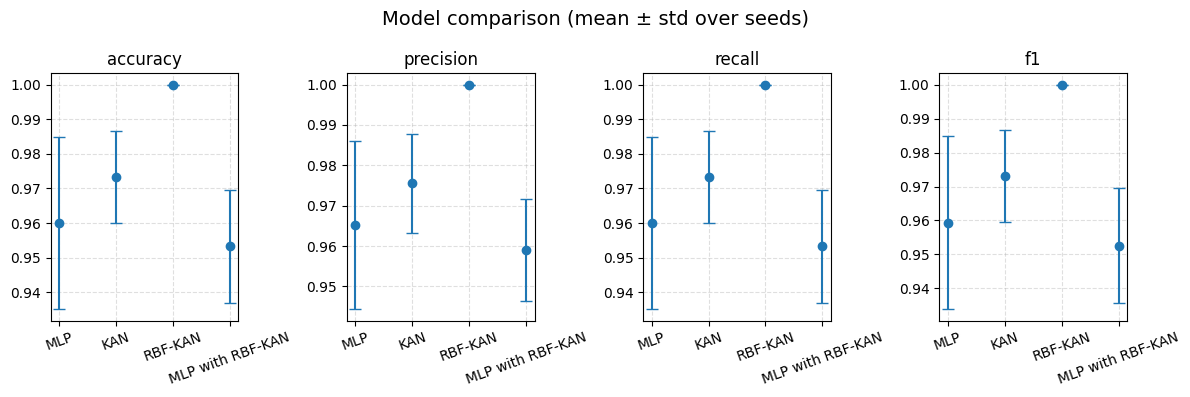

In [20]:

input_dim = 4 
hidden_dim = 32 
output_dim = 3 
centers = 8 # or Knots
domain = (-3, 3)
shared_basis = True

# Models definition
models = {
    "MLP": lambda: MLP(input_dim, hidden_dim, output_dim),
    "KAN": lambda: KAN(
        width=[input_dim, hidden_dim, hidden_dim, output_dim],
        num_knots=centers,
        domain=domain
    ),
    "RBF-KAN": lambda: RBF_KAN(input_dim, hidden_dim, output_dim, centers, domain),
    "MLP with RBF-KAN": lambda: MLP_RBFKAN(
        in_dim=input_dim,
        hidden_dim=hidden_dim,
        out_dim=output_dim,
        num_centers=centers,
        domain=domain,
        shared_basis=True
    )
}

# Configurazione esperimento
cfg = ExperimentCfg(
    models=models,
    seeds=[2,235,1,43,89],
    epochs=20, 
    mlp_lr=1e-3,
    kan_lr=1e-3,
    batch_size=64,
    mlp_optimizer="adam",
    kan_optimizer="adam",
    device=device,
    domain=domain,
    test_loader=test_loader,
    train_loader=train_loader,
)

runner = ExperimentalRunner(cfg)
runner.run_battery_experiments()
runner.plot_metrics_summary()